# Measurement error in SAM totals

{cite:t}`byron-1978` balances a five-account SAM from Stone (1976) whose cells and account totals are both estimates with standard errors. The balanced SAM is the weighted least squares estimate: each cell is held near its estimate in proportion to its precision, each account's income is held near its measured total in the same way, and the accounting identities hold exactly. This is `fit` with the `cg.LeastSquares` objective and a `.normal` measurement on each measured total. This notebook reproduces the paper's Tables 1 and 2.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import HTML
from matplotlib.patches import FancyArrowPatch

import cge_modeling as cg

In [2]:
caption_style = [{"selector": "caption",
                  "props": "caption-side: top; font-weight: bold; text-align: left"}]


def cell_color(value):
    if value == 0.0:
        return "color: lightgray"
    if value < 0.0:
        return "color: firebrick"
    return ""


def style_table(frame, precision, caption):
    return (frame.style
            .format(precision=precision, na_rep="")
            .map(cell_color)
            .set_caption(caption)
            .set_table_styles(caption_style))


def style_comparison(frame, caption, limit):
    """Shade the difference column from blue at -limit through white at zero to red at +limit."""
    return (frame.style
            .format(precision=2)
            .background_gradient(cmap="RdBu_r",
                                 subset=["difference"],
                                 vmin=-limit,
                                 vmax=limit)
            .set_caption(caption)
            .set_table_styles(caption_style))


def style_difference(frame, caption, limit):
    """Shade every cell from blue at -limit through white at zero to red at +limit, leaving NaN cells blank."""
    return (frame.style
            .format(precision=2, na_rep="")
            .background_gradient(cmap="RdBu_r",
                                 vmin=-limit,
                                 vmax=limit)
            .highlight_null(color="transparent")
            .set_caption(caption)
            .set_table_styles(caption_style))


def three_panels(top_left, top_right, bottom):
    """Lay out two tables side by side, with a third centered below them."""
    return HTML('<div style="display: inline-grid; grid-template-columns: max-content max-content; gap: 1.5em 3em">'
                f"<div>{top_left.to_html()}</div>"
                f"<div>{top_right.to_html()}</div>"
                f'<div style="grid-column: 1 / 3; justify-self: center">{bottom.to_html()}</div>'
                "</div>")

## The data

Table 1 of the paper has one labor account, two household accounts and two production accounts. The paper labels the household and production accounts only by group, and here they are numbered 1 and 2. Ten cells have an estimate and a standard error. The two payments from labor to the households are nonzero but have no estimate. Three accounts have a measured total income with its own standard error.

In [3]:
accounts = ["Labor", "Households 1", "Households 2", "Production 1", "Production 2"]

table_1 = pd.DataFrame(data=[("Labor", "Households 1", 15.0, 6.0),
                             ("Labor", "Households 2", 3.0, 1.2),
                             ("Labor", "Production 1", 130.0, 26.0),
                             ("Labor", "Production 2", 80.0, 16.0),
                             ("Production 1", "Households 1", 15.0, 6.0),
                             ("Production 1", "Households 2", 130.0, 52.0),
                             ("Production 1", "Production 2", 20.0, 14.0),
                             ("Production 2", "Households 1", 25.0, 2.5),
                             ("Production 2", "Households 2", 40.0, 16.0),
                             ("Production 2", "Production 1", 55.0, 11.0)],
                       columns=["row", "col", "estimate", "standard error"]).set_index(["row", "col"])
wages = [("Households 1", "Labor"), ("Households 2", "Labor")]

totals = pd.DataFrame(data={"estimate": [220.0, 190.0, 105.0],
                            "standard error": [22.0, 38.0, 21.0]},
                      index=["Labor", "Production 1", "Production 2"])

style_table(table_1,
            precision=1,
            caption="Table 1: cell estimates, rows receive from columns")

In [4]:
style_table(totals,
            precision=1,
            caption="Table 1: measured total income")

,estimate,standard error
Labor,220.0,22.0
Production 1,190.0,38.0
Production 2,105.0,21.0


## The model

`cg.LeastSquares` minimizes

$$
\frac{1}{2} \sum_k \left( \frac{x_k - z_k}{\sigma_k} \right)^2 + \frac{1}{2} \sum_i \left( \frac{\sum_j x_{ij} - t_i}{s_i} \right)^2
$$

over the cells $x_k$, where $z_k$ is a cell's estimate with standard error $\sigma_k$, and $t_i$ is the measured total income of account $i$ with standard error $s_i$. The first sum is the objective, with `sigma` holding each cell's standard error in that cell. The second comes from `.normal(sigma=...)` on the comparison of each account's income with its measured total. Byron makes each total a variable with its own estimate. A total enters the identities only through its own account, so that is the same as a normal measurement of the account's income.

The wage cells need a nonzero prior so that the SAM has them. They get a placeholder of 1 and a standard error of $10^6$, so their prior carries no weight, as in Byron, who lets their prior variance go to infinity.

In [5]:
prior = pd.DataFrame(0.0,
                     index=accounts,
                     columns=accounts)
sigma = pd.DataFrame(np.nan,
                     index=accounts,
                     columns=accounts)
for (row, column), cell in table_1.iterrows():
    prior.loc[row, column] = cell["estimate"]
    sigma.loc[row, column] = cell["standard error"]
for row, column in wages:
    prior.loc[row, column] = 1.0
    sigma.loc[row, column] = 1e6

style_table(sigma,
            precision=1,
            caption="sigma: standard error of each cell estimate")

,Labor,Households 1,Households 2,Production 1,Production 2
Labor,,6.0,1.2,26.0,16.0
Households 1,1000000.0,,,,
Households 2,1000000.0,,,,
Production 1,,6.0,52.0,,14.0
Production 2,,2.5,16.0,11.0,


`sam.sum("col")` is the income of every account. Comparing it with the Series of measured totals aligns them by label. The two household accounts have no measured total, so their entries are missing and impose nothing.

In [6]:
sam = cg.SymbolicSAM(prior)
sam.subject_to(measured_totals=(sam.sum("col") == totals["estimate"]).normal(sigma=totals["standard error"]))
estimate = sam.fit(objective=cg.LeastSquares(sigma=sigma))

table_2 = pd.DataFrame(data=[("Labor", "Households 1", 14.45, 5.89),
                             ("Labor", "Households 2", 2.98, 1.2),
                             ("Labor", "Production 1", 124.12, 16.02),
                             ("Labor", "Production 2", 85.84, 10.36),
                             ("Households 1", "Labor", 54.35, 8.71),
                             ("Households 2", "Labor", 173.04, 16.99),
                             ("Production 1", "Households 1", 15.13, 5.96),
                             ("Production 1", "Households 2", 139.65, 17.51),
                             ("Production 1", "Production 2", 20.60, 3.92),
                             ("Production 2", "Households 1", 24.77, 2.48),
                             ("Production 2", "Households 2", 30.42, 11.22),
                             ("Production 2", "Production 1", 51.26, 9.45)],
                       columns=["row", "col", "estimate", "standard error"]).set_index(["row", "col"])

published_sam = pd.DataFrame(0.0,
                             index=accounts,
                             columns=accounts)
for (row, column), cell in table_2.iterrows():
    published_sam.loc[row, column] = cell["estimate"]

three_panels(style_table(published_sam,
                         precision=2,
                         caption="Table 2"),
             style_table(estimate.sam,
                         precision=2,
                         caption="Reproduced, standard errors as printed"),
             style_difference((estimate.sam - published_sam).where(prior != 0.0),
                              caption="Reproduced minus Table 2",
                              limit=5.0))

,Labor,Households 1,Households 2,Production 1,Production 2
Labor,0.00,14.45,2.98,124.12,85.84
Households 1,54.35,0.00,0.00,0.00,0.00
Households 2,173.04,0.00,0.00,0.00,0.00
Production 1,0.00,15.13,139.65,0.00,20.60
Production 2,0.00,24.77,30.42,51.26,0.00
,Labor,Households 1,Households 2,Production 1,Production 2
Labor,0.00,14.54,2.98,125.57,83.05
Households 1,54.43,0.00,0.00,0.00,0.00
Households 2,171.71,0.00,0.00,0.00,0.00
Production 1,0.00,15.09,136.99,0.00,25.33


With the inputs as printed, the estimate differs from Table 2 by up to 4.7, in the cell from Production 2 to Production 1. Table 2 also satisfies every identity, so the two differ in what they minimize. `sam.objective_value` evaluates the objective of `sam`, including the measured totals, at any SAM with the prior's layout. At Table 2 it is higher than at the estimate, so Table 2 is not the minimum for the printed inputs.

In [7]:
least_squares = cg.LeastSquares(sigma=sigma)
objectives = pd.DataFrame({"objective": [sam.objective_value(published_sam, objective=least_squares),
                                         estimate.objective]},
                          index=["at Table 2", "at the reproduced estimate"])

style_table(objectives,
            precision=3,
            caption="Objective with the standard errors as printed")

,objective
at Table 2,0.489
at the reproduced estimate,0.402


## Standard errors inferred from Table 2

Fitting all 13 standard errors so that the weighted least squares estimate and its standard errors match Table 2 returns ten of them within about 1% of Table 1. The other three differ:

| quantity | Table 1 | fitted to Table 2 |
|---|---|---|
| standard error of the cell from Production 2 to Production 1 | 14 | 4.00 |
| standard error of the cell from Production 2 to Labor | 16 | 18.05 |
| standard error of the total of Production 2 | 21 | 17.99 |

The first is the clearest case. Table 2 gives that cell a standard error of 3.92, and a prior standard error of 14 cannot shrink that far under these identities, while a printed 4 can. The rest of this notebook uses 4, 18 and 18, inferred from Table 2 and not printed in Table 1.

In [8]:
corrected_sigma = sigma.copy()
corrected_sigma.loc["Production 1", "Production 2"] = 4.0
corrected_sigma.loc["Labor", "Production 2"] = 18.0
corrected_errors = totals["standard error"].copy()
corrected_errors["Production 2"] = 18.0

corrected = cg.SymbolicSAM(prior)
corrected.subject_to(measured_totals=(corrected.sum("col") == totals["estimate"]).normal(sigma=corrected_errors))
corrected_estimate = corrected.fit(objective=cg.LeastSquares(sigma=corrected_sigma))

three_panels(style_table(published_sam,
                         precision=2,
                         caption="Table 2"),
             style_table(corrected_estimate.sam,
                         precision=2,
                         caption="Reproduced, inferred standard errors"),
             style_difference((corrected_estimate.sam - published_sam).where(prior != 0.0),
                              caption="Reproduced minus Table 2",
                              limit=5.0))

,Labor,Households 1,Households 2,Production 1,Production 2
Labor,0.00,14.45,2.98,124.12,85.84
Households 1,54.35,0.00,0.00,0.00,0.00
Households 2,173.04,0.00,0.00,0.00,0.00
Production 1,0.00,15.13,139.65,0.00,20.60
Production 2,0.00,24.77,30.42,51.26,0.00
,Labor,Households 1,Households 2,Production 1,Production 2
Labor,0.00,14.45,2.98,124.13,85.82
Households 1,54.35,0.00,0.00,0.00,0.00
Households 2,173.03,0.00,0.00,0.00,0.00
Production 1,0.00,15.13,139.66,0.00,20.59


## Standard errors of the balanced SAM

`corrected_estimate.covariance()` is the covariance of the balanced cells under the same normal model. The standard error of an account's total income is the square root of the sum of the covariance block for that account's row.

In [9]:
covariance = corrected_estimate.covariance()
cell_errors = pd.Series(np.sqrt(np.diag(covariance)), index=covariance.index)

cell_comparison = pd.DataFrame({"published": table_2["standard error"],
                                "reproduced": cell_errors[table_2.index]})
cell_comparison["difference"] = cell_comparison["reproduced"] - cell_comparison["published"]

style_comparison(cell_comparison,
                 caption="Standard errors of the balanced cells, against Table 2",
                 limit=0.5)

In [10]:
receiving_account = covariance.index.get_level_values("row")
total_errors = {account: np.sqrt(covariance.loc[receiving_account == account, receiving_account == account].to_numpy().sum())
                for account in accounts}
total_errors["All accounts"] = np.sqrt(covariance.to_numpy().sum())

total_comparison = pd.DataFrame({"published": [15.94, 8.71, 16.99, 16.60, 10.35, 47.88],
                                 "reproduced": pd.Series(total_errors)})
total_comparison["difference"] = total_comparison["reproduced"] - total_comparison["published"]

style_comparison(total_comparison,
                 caption="Standard errors of total income, against Table 2",
                 limit=0.5)

,published,reproduced,difference
Labor,15.94,15.95,0.01
Households 1,8.71,8.71,0.00
Households 2,16.99,17.00,0.01
Production 1,16.60,16.61,0.01
Production 2,10.35,10.30,-0.05
All accounts,47.88,47.87,-0.01


With the three inferred standard errors, every cell matches Table 2 within 0.03, and every standard error, of a cell or a total, within 0.07.

## References

```{bibliography}
```

## Authors

- Created by Jesse Grabowski, November 22, 2026

## Watermark

In [11]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Wed, 25 Nov 2026

Python implementation: CPython
Python version       : 3.12.13
IPython version      : 9.18.1

Compiler    : Clang 19.1.7 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

IPython     : 9.18.1
cge_modeling: 0.0.7.dev15+g93cb61e4e.d20261120
matplotlib  : 3.11.2
numpy       : 2.3.5
pandas      : 3.1.1

Watermark: 2.6.0



# Thumbnail Image

The cell below draws this notebook's card image for the docs gallery: the five accounts with each cell as an arrow from payer to receiver, colored by how balancing with the inferred standard errors moved it from its Table 1 estimate. Its `gallery-thumbnail` tag selects it as the thumbnail, and its `remove-cell` tag, shared with this heading, keeps both off the rendered page.

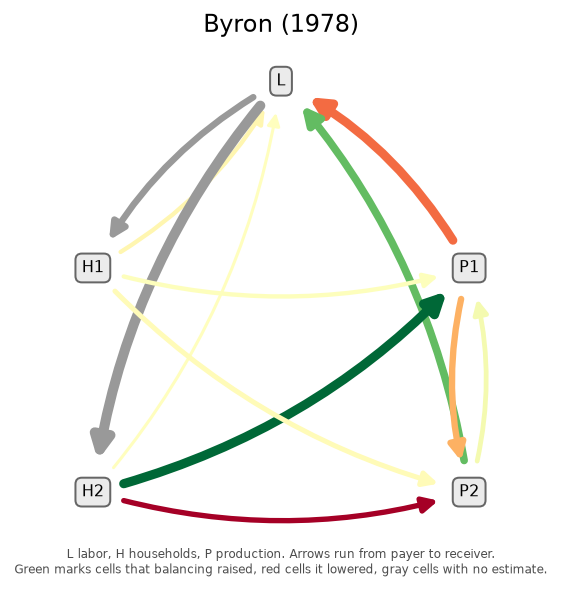

In [12]:
account_positions = {"Labor": np.array([1.0, 1.0]),
                     "Households 1": np.array([0.0, 0.0]),
                     "Households 2": np.array([0.0, -1.2]),
                     "Production 1": np.array([2.0, 0.0]),
                     "Production 2": np.array([2.0, -1.2])}
short_names = {"Labor": "L", "Households 1": "H1", "Households 2": "H2", "Production 1": "P1", "Production 2": "P2"}
balanced = corrected_estimate.sam
change = (balanced - prior).where(sigma < 1e6)
largest_change = np.nanmax(np.abs(change.to_numpy()))
colormap = plt.get_cmap("RdYlGn")

fig, ax = plt.subplots(figsize=(4, 4), dpi=144, layout="constrained")
for receiver, payer in table_2.index:
    start, end = account_positions[payer], account_positions[receiver]
    # The wage cells have no estimate to move from, so they are drawn in gray.
    color = ("0.6" if (receiver, payer) in wages
             else colormap(0.5 + 0.5 * change.loc[receiver, payer] / largest_change))
    width = 1.0 + 4.0 * np.sqrt(balanced.loc[receiver, payer] / balanced.to_numpy().max())
    ax.add_patch(FancyArrowPatch(posA=start,
                                 posB=end,
                                 arrowstyle="-|>",
                                 mutation_scale=10 + 2 * width,
                                 linewidth=width,
                                 color=color,
                                 shrinkA=16,
                                 shrinkB=16,
                                 connectionstyle="arc3,rad=0.15"))
for account, position in account_positions.items():
    ax.annotate(short_names[account],
                xy=position,
                ha="center",
                va="center",
                fontsize=8,
                bbox={"boxstyle": "round,pad=0.4", "facecolor": "0.92", "edgecolor": "0.4"})

ax.set(xlim=(-0.35, 2.35),
       ylim=(-1.45, 1.2),
       title="Byron (1978)")
ax.set_axis_off()
ax.annotate(text="L labor, H households, P production. Arrows run from payer to receiver.\n"
                 "Green marks cells that balancing raised, red cells it lowered, gray cells with no estimate.",
            xy=(0.5, 0.0),
            xycoords="axes fraction",
            xytext=(0, -4),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=6,
            color="0.3")
plt.show()